# 足球 xG：实际训练与验证
数据：StatsBomb Open Data，2015/16 英超。依次执行以下单元；只从射门发生时的特征估计条件进球概率。

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from main import load_data, make_model, evaluate, fit, ROOT
df, split_info = load_data()
print(split_info)
df.groupby("split").agg(射门数=("goal","size"), 进球数=("goal","sum"), 比赛数=("match_id","nunique"))

{'validation_start': '2016-02-02', 'test_start': '2016-04-10', 'invalid_excluded': 1}


,射门数,进球数,比赛数
split,,,
test,1649,180,60
train,5906,579,230
validation,2352,228,90


## 1. 条件概率与特征
$Y\mid X=x\sim\operatorname{Bernoulli}(p(x))$。距离和角度从射门坐标计算；编码与标准化只在训练集拟合。

In [2]:
df[["x","y","distance","angle","body_part","shot_type","under_pressure","first_time","goal"]].head(8)

## 2. 亲手拟合一个模型
主模型排除点球。先拟合 $C=1$ 的逻辑回归，再运行完整的验证集选参、校准与测试流程。

In [3]:
shots = df[df.shot_type != "Penalty"]
train = shots[shots.split == "train"]
val = shots[shots.split == "validation"]
model = make_model(C=1, context=True)
model.fit(train, train.goal)
evaluate(val.goal, model.predict_proba(val)[:,1])

{'log_loss': 0.2819627592213138,
 'brier': 0.07954759206576718,
 'auc': 0.7271789305176365,
 'mean_xg': 0.09302100013394976,
 'goal_rate': 0.0920376712328767,
 'sum_xg': 217.29705631290665,
 'goals': 215}

In [4]:
encoder = model.named_steps["features"]
pd.DataFrame({"特征":encoder.get_feature_names_out(),"系数":model.named_steps["model"].coef_[0]})

,特征,系数
0,numeric__distance,-0.976666
1,numeric__angle,0.352232
2,category__body_part_Head,-0.813730
3,category__body_part_Left Foot,0.173809
4,category__body_part_Other,0.020442
5,category__body_part_Right Foot,0.443034
6,category__shot_type_Free Kick,0.216042
7,category__shot_type_Open Play,-0.392486
8,binary__under_pressure,-0.290881
9,binary__first_time,-0.279691


## 3. 完整训练与独立验证
以下真正重新拟合候选模型，使用验证集选择参数，再生成测试结果和按比赛重抽样的区间。

In [5]:
fit()
summary = json.loads((ROOT / "results/summary.json").read_text(encoding="utf-8"))
pd.DataFrame(summary["metrics"]).T

{
  "seed": 20261013,
  "total_valid_shots": 9907,
  "nonpenalty_shots": 9816,
  "penalty_shots": 91,
  "split": {
    "validation_start": "2016-02-02",
    "test_start": "2016-04-10",
    "invalid_excluded": 1
  },
  "split_summary": {
    "train": {
      "matches": 230,
      "nonpenalty_shots": 5851,
      "nonpenalty_goals": 532,
      "first_date": "2015-08-08",
      "last_date": "2016-01-24"
    },
    "validation": {
      "matches": 90,
      "nonpenalty_shots": 2336,
      "nonpenalty_goals": 215,
      "first_date": "2016-02-02",
      "last_date": "2016-04-09"
    },
    "test": {
      "matches": 60,
      "nonpenalty_shots": 1629,
      "nonpenalty_goals": 166,
      "first_date": "2016-04-10",
      "last_date": "2016-05-17"
    }
  },
  "selected": {
    "geometry": {
      "model": "geometry",
      "C": 0.01,
      "validation_log_loss": 0.2878917508560916
    },
    "context": {
      "model": "context",
      "C": 10.0,
      "validation_log_loss": 0.28176545095699

,log_loss,brier,auc,mean_xg,goal_rate,sum_xg,goals
constant,0.329948,0.091639,0.500000,0.090925,0.101903,148.116219,166.0
geometry,0.298391,0.085508,0.737406,0.092500,0.101903,150.682128,166.0
context,0.288489,0.083224,0.761939,0.091131,0.101903,148.452937,166.0
context_calibrated,0.290018,0.083551,0.761939,0.090682,0.101903,147.720784,166.0


In [6]:
pred = pd.read_csv(ROOT / "results/test_predictions.csv")
assert set(train.match_id).isdisjoint(pred.match_id)
assert train.date.max() < val.date.min() < pred.date.min()
print("不同集合无比赛重叠，时间顺序检查通过")
pred[["home","away","minute","distance","angle","goal","xg"]].head(12)

## 4. 图形验证
AUC 看排序，校准图检查概率大小。分组进球率有抽样波动，不能要求每个点恰好落在对角线上。

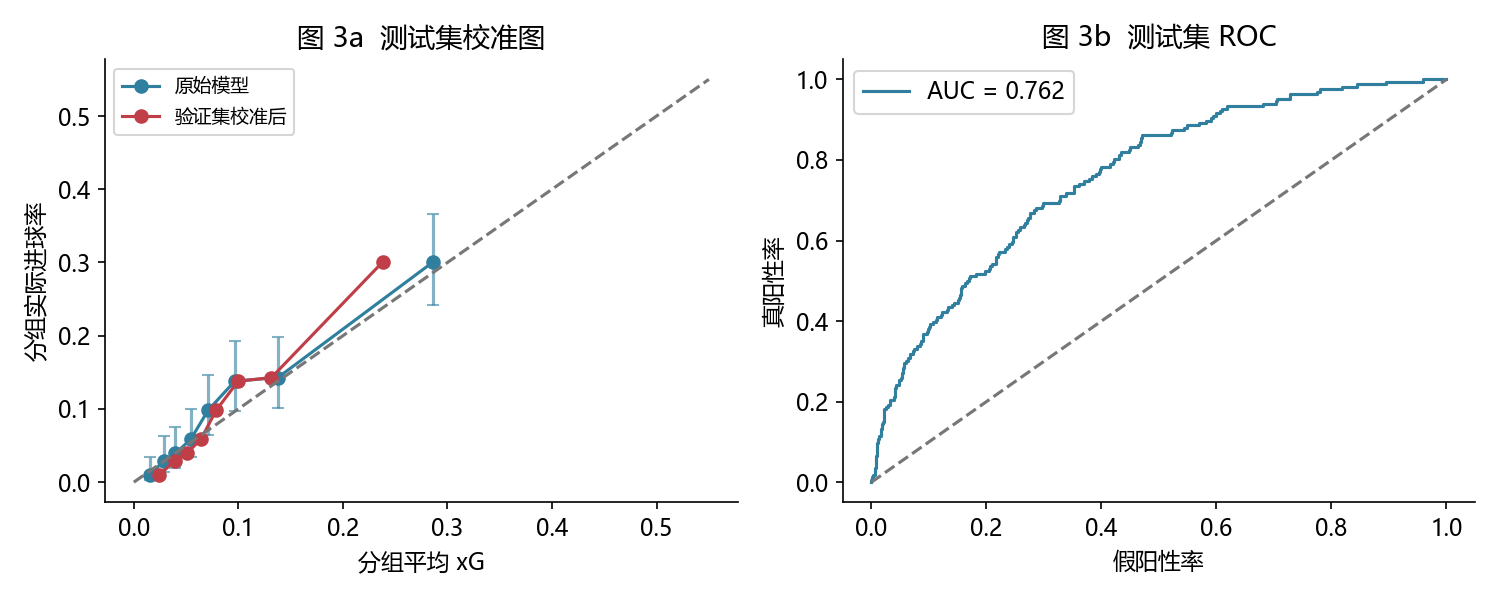

{'log_loss': [0.25930970483278526, 0.3199989771487896],
 'brier': [0.07306573476987158, 0.09384723157707187],
 'auc': [0.729456116125496, 0.7952604419530392],
 'brier_gain_vs_constant': [0.004616390381197815, 0.012141890954496012]}

In [7]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "assets/03_validation.png")))
summary["match_bootstrap_95ci"]

## 5. xG 总和与真实进球
期望具有线性性。按射门自身特征估计的概率总和，是比赛机会质量的近似评价；它不是承诺实际进球数。

In [8]:
pred.groupby(["match_id","home","away"]).agg(射门数=("goal","size"), 实际进球=("goal","sum"), 非点球xG=("xg","sum")).head(12)

,,,射门数,实际进球,非点球xG
match_id,home,away,,,
3753986,Liverpool,Stoke City,25,5,2.140271
3753989,Sunderland,Everton,32,3,3.639042
3753990,Sunderland,Arsenal,32,0,2.967733
3753992,Tottenham Hotspur,Southampton,29,3,3.118594
3753994,Southampton,Crystal Palace,34,4,2.412825
3754009,Arsenal,Crystal Palace,28,2,2.263330
3754018,Swansea City,Liverpool,29,4,2.254704
3754024,Newcastle United,Swansea City,24,3,2.246076
3754026,Crystal Palace,Stoke City,29,3,1.761719


## 6. 点球的贝叶斯估计
若先验为 Beta(1,1)，后验预测概率为 $(k+1)/(n+2)$。

In [9]:
pen = df[(df.shot_type == "Penalty") & (df.split == "train")]
n, k = len(pen), int(pen.goal.sum())
print(f"训练点球：{n} 次，进球 {k} 次；后验预测概率 {(k+1)/(n+2):.3f}")

训练点球：55 次，进球 47 次；后验预测概率 0.842


## 思考
- 为什么高分类准确率不足以验证 xG？
- 校准之后测试损失是否一定下降？
- 若加入射门终点坐标，预测任务的含义会怎样变化？

数据许可见 data/LICENSE.pdf。AI 辅助编写，实验结果来自实际运行。